Follow-up concept: testing whether validating on a higher-volatility period works better for 2026.

In [1]:
import sys
sys.path.append("..")
import itertools
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from src.data import load_dataset
from src.backtest import walk_forward
from src.features import make_lag_features
from src.models import random_walk_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models_staggered, accuracy_metrics, dm_table, plot_forecasts

H = 1   # forecast horizon: 1 in this notebook, 5 in the other

data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"]  # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]  # fear/uncertainty indices -> log levels
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]
X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]


/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [4]:
from src.features import garch_volatility

volatility = garch_volatility(df_var, col="log_return") * 100   # daily GARCH vol in %
periods = {
    "Validation 2024-25": volatility["2024-01-01":"2025-12-31"],
    "Validation 2022": volatility["2022-01-01":"2022-12-31"],
    "Test Jan-Sep 2026": volatility["2026-01-01":"2026-09-30"],
}

vol_table = pd.DataFrame({name: {"Average vol %": v.mean(), "Median vol %": v.median(), "Max vol %": v.max()}
                          for name, v in periods.items()}).T
vol_table["Gap to test average"] = vol_table.loc["Test Jan-Sep 2026", "Average vol %"] - vol_table["Average vol %"]
vol_table.round(2)


,Average vol %,Median vol %,Max vol %,Gap to test average
Validation 2024-25,1.87,1.78,3.71,2.13
Validation 2022,2.90,2.67,5.50,1.11
Test Jan-Sep 2026,4.01,3.90,7.19,0.00


We see 2022 has a closer volatility to the rockier average of 2026.

VAR 

In [2]:
from statsmodels.tsa.api import VAR                # the VAR model used for the Granger test

pre = X[X.index < "2022-01-01"]                    # only data before validation, so no peeking
pre_var = pre.reset_index(drop=True)               # drop the dates to stop statsmodels warnings
order = VAR(pre_var).select_order(maxlags=10)      # try lags up to 10
var_fit = VAR(pre_var).fit(order.bic)              # fit using the lag BIC picks
granger = pd.Series({col: var_fit.test_causality(caused="brent_spot", causing=[col], kind="f").pvalue
                     for col in pre.columns if col != "brent_spot"}).sort_values()   # p-value per variable, smallest first
print(granger)

STAGES = {                                         # log_return stays first: var_forecast reads column 0 as Brent
    "S1": ["log_return"] + list(granger[granger < 0.001].index),      # strongest variables
    "S2": ["log_return"] + list(granger[granger < 0.05 / 8].index),   # pass the Bonferroni cut
    "S3": ["log_return"] + list(granger[granger < 0.5].index),        # everything except the clearly useless
}
print(STAGES)


wti                   2.137378e-43
usd                   3.116949e-04
epu                   1.181989e-03
vix                   3.723588e-03
sp500                 1.880616e-02
invt_weekly_change    3.321201e-02
ovx                   6.055691e-02
gpr                   6.134008e-01
dtype: float64
{'S1': ['log_return', 'wti', 'usd'], 'S2': ['log_return', 'wti', 'usd', 'epu', 'vix'], 'S3': ['log_return', 'wti', 'usd', 'epu', 'vix', 'sp500', 'invt_weekly_change', 'ovx']}


WTI and USD are strongest (p < 0.001). EPU and VIX also pass the Bonferroni cut (5%/8 = 0.00625). S&P 500, inventory and OVX are weaker, and GPR is clearly not useful (p = 0.61).

In [5]:
val_args = dict(horizon=H, start_date="2022-01-01", end_date="2022-12-31", target_end_date="2022-12-31")

results = {"Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args)}

for stage, cols in STAGES.items():
    for p in range(1, 6):
        results[f"VAR {stage} p={p}"] = walk_forward(df_var, forecast_funct=var_forecast, cols=cols, lags=p, **val_args)


In [6]:
table = compare_models_staggered(results, horizon=H)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / table.loc["Random Walk", m]) * 100
table.round(4).sort_values("MAPE")

,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,
VAR S1 p=1,2.2969,3.1932,2.2319,0.5538,-0.0266,1.7692,-0.1305,1.7389
VAR S2 p=1,2.3098,3.2049,2.2451,0.5020,-1.3939,1.2181,-0.4998,1.1582
VAR S1 p=2,2.3212,3.2177,2.2517,0.5259,-0.5810,0.7294,-0.8987,0.8672
VAR S3 p=1,2.3224,3.2220,2.2565,0.5179,-1.1475,0.6785,-1.0348,0.6587
VAR S2 p=2,2.3287,3.2191,2.2597,0.5219,0.1084,0.4092,-0.9450,0.5152
VAR S3 p=2,2.3351,3.2409,2.2653,0.5339,0.5744,0.1342,-1.6282,0.2685
Random Walk,2.3383,3.1890,2.2714,0.0040,NaN,0.0000,0.0000,0.0000
VAR S3 p=4,2.3433,3.2159,2.2742,0.5299,0.9181,-0.2152,-0.8440,-0.1243
VAR S2 p=5,2.3472,3.2074,2.2758,0.4900,0.2937,-0.3833,-0.5773,-0.1942


In [7]:
val_args = dict(horizon=H, start_date="2022-01-01", end_date="2022-12-31", target_end_date="2022-12-31")
TIE = 0.002   # a variable must cut MAPE by more than this to be added

rw = walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args)
best_mape = accuracy_metrics(rw)["MAPE"]   # starting point: the random walk
best_lag = None
print(f"Random walk MAPE: {best_mape:.4f}")

selected = ["log_return"]
remaining = ["wti", "usd", "sp500", "vix", "ovx", "epu", "gpr", "invt_weekly_change"]

while remaining:
    jobs = [(var, lag) for var in remaining for lag in range(1, 6)]
    runs = Parallel(n_jobs=-1)(
        delayed(walk_forward)(df_var, forecast_funct=var_forecast, cols=selected + [var], lags=lag, **val_args)
        for var, lag in jobs
    )
    scores = pd.DataFrame([{"var": var, "lag": lag, "MAPE": accuracy_metrics(r)["MAPE"]}
                           for (var, lag), r in zip(jobs, runs)])
    best = scores.loc[scores["MAPE"].idxmin()]
    print(f"Round {len(selected)}: best add = {best['var']} (lag={best['lag']}), MAPE {best['MAPE']:.4f} vs current {best_mape:.4f}")
    if best["MAPE"] > best_mape - TIE:
        print("Improvement < 0.002, not useful anymore, stop.")
        break
    selected.append(best["var"])
    remaining.remove(best["var"])
    best_mape, best_lag = best["MAPE"], best["lag"]

print("Selected:", selected, "lag =", best_lag)


Random walk MAPE: 2.2714
Round 1: best add = ovx (lag=4), MAPE 2.2255 vs current 2.2714
Round 2: best add = epu (lag=5), MAPE 2.2255 vs current 2.2255
Improvement < 0.002, not useful anymore, stop.
Selected: ['log_return', 'ovx'] lag = 4


In [8]:
stage_rows = table[table.index.str.startswith("VAR")]
print(f"Best hierarchical: {stage_rows['MAPE'].idxmin()}, MAPE {stage_rows['MAPE'].min():.4f}")
print(f"Forward selection: {selected}, lag {best_lag}, MAPE {best_mape:.4f}")


Best hierarchical: VAR S1 p=1, MAPE 2.2319
Forward selection: ['log_return', 'ovx'], lag 4, MAPE 2.2255


Forward Selection (FS) won with MAPE 2.2255 (+2.02% vs RW), against the best hierarchical model, VAR S1 p=1, at 2.2319 (+1.74%). The gap of 0.0064 is above our 0.002 tie, so we use the FS model: ovx, lag 4.

XGBoost

In [9]:
feats_fs = make_lag_features(df_var, selected, lags=best_lag)   # same variables and same days as the VAR

grid = [dict(n_estimators=n, max_depth=d, min_child_weight=m)
        for n, d, m in itertools.product([50, 200], [1, 2], [1, 100])]
runs = Parallel(n_jobs=-1)(
    delayed(walk_forward)(df_var, forecast_funct=xgb_forecast, features=feats_fs, **g, **val_args) for g in grid
)

mapes = [accuracy_metrics(r)["MAPE"] for r in runs]
xgb_params = grid[np.argmin(mapes)]   # the settings with the smallest MAPE
print("Best XGB:", xgb_params, f"MAPE {min(mapes):.4f}")


Best XGB: {'n_estimators': 50, 'max_depth': 1, 'min_child_weight': 100} MAPE 2.2702


On Test set:

Jan-Sep 2026 n = 188


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAPE_vs_RW_%
model,,,,,,
Random Walk,3.1874,4.4360,3.2566,0.0000,NaN,0.0000
VAR,3.1887,4.4866,3.2692,0.5213,-0.1802,-0.3888
XGB,3.2378,4.5090,3.3125,0.4521,-0.7308,-1.7162


,DM_stat,p_value,n
VAR,0.3159,0.7524,188.0
XGB,1.6994,0.0909,188.0


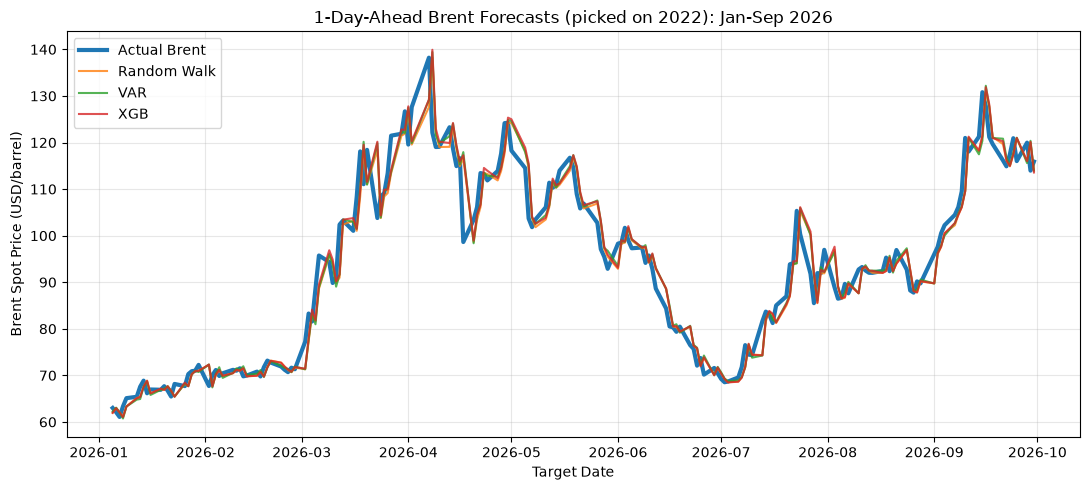

October 2026 n = 16


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAPE_vs_RW_%
model,,,,,,
XGB,4.0367,6.6332,3.1716,0.7500,3.4771,0.7669
Random Walk,4.0675,6.6324,3.1962,0.0000,NaN,0.0000
VAR,4.0925,6.6228,3.2214,0.4375,-2.6301,-0.7916


,DM_stat,p_value,n
VAR,0.2130,0.8342,16.0
XGB,-0.5662,0.5796,16.0


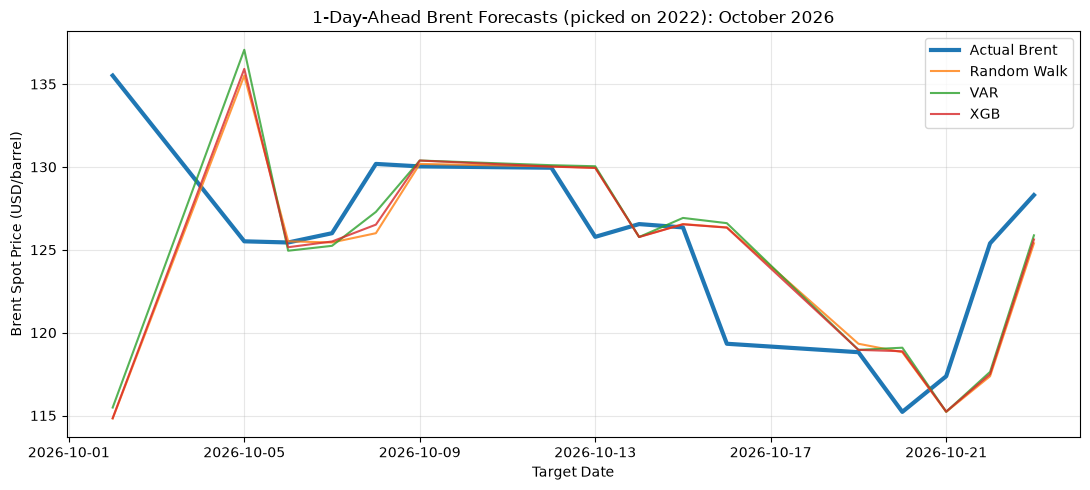

In [11]:
TESTS = {
    "Jan-Sep 2026": dict(start_date="2026-01-01", end_date="2026-09-30", target_end_date="2026-09-30"),
    "October 2026": dict(start_date="2026-10-01", end_date="2026-10-23", target_end_date="2026-10-23", fit_end_date="2026-09-30"),
}

all_results = {}   # stores each test's results for plotting later
for label, dates in TESTS.items():
    test_args = dict(horizon=H, **dates)
    test_results = {
        "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **test_args),
        "VAR": walk_forward(df_var, forecast_funct=var_forecast, cols=selected, lags=best_lag, **test_args),
        "XGB": walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_fs, **xgb_params, **test_args),
    }
    all_results[label] = test_results   # save this test before the next pass overwrites it

    table = compare_models_staggered(test_results, horizon=H)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
    table["MAPE_vs_RW_%"] = (1 - table["MAPE"] / table.loc["Random Walk", "MAPE"]) * 100

    print(label, "n =", len(test_results["Random Walk"]))
    display(table.round(4).sort_values("MAPE"))
    display(dm_table(test_results, horizon=H).round(4))   # -ve DM stat = errors smaller than RW
    plot_forecasts(test_results, f"{H}-Day-Ahead Brent Forecasts (picked on 2022): {label}")



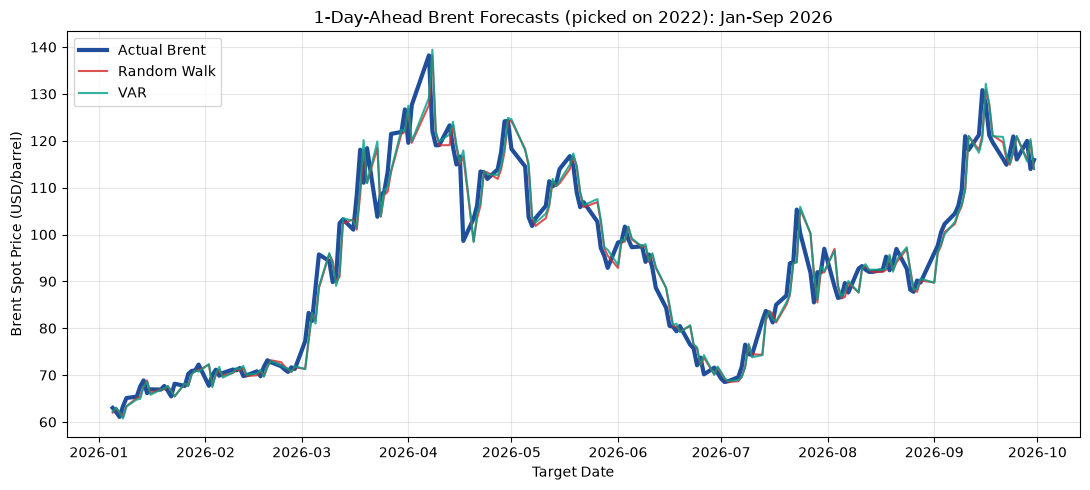

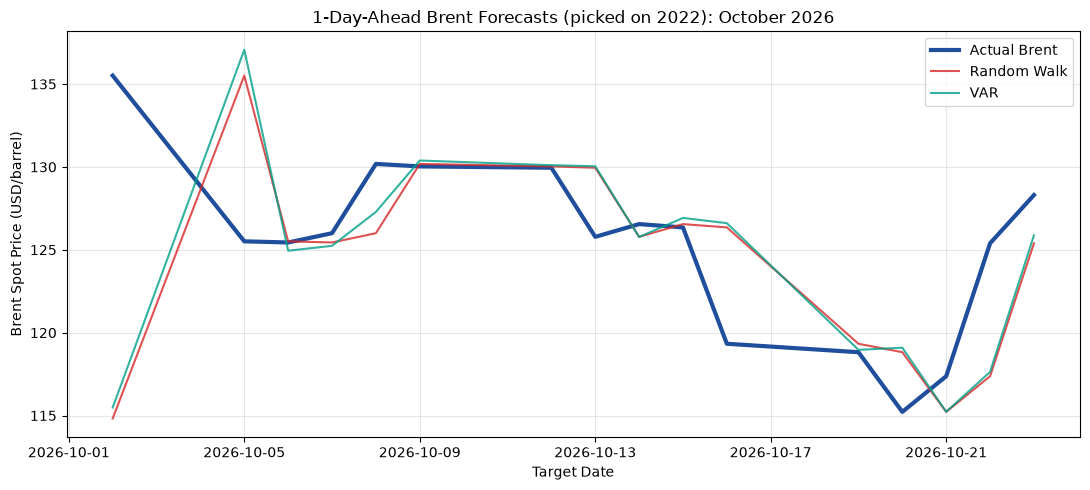

In [16]:
models = ["Random Walk", "VAR"]

plot_forecasts(all_results["Jan-Sep 2026"], f"{H}-Day-Ahead Brent Forecasts (picked on 2022): Jan-Sep 2026", models=models)
plot_forecasts(all_results["October 2026"], f"{H}-Day-Ahead Brent Forecasts (picked on 2022): October 2026", models=models)
